## Importation data

In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
full = pd.read_csv(BASE + "training_data.csv")
test = pd.read_csv(BASE + "testing_data.csv") # scellé jusqu&#39;à la Partie F

full["id"], test["id"] = range(len(full)), range(len(test))
train, val = train_test_split(full, test_size=0.10, random_state=42,stratify=full["sarcasm"])

## Visualisation Data

In [6]:
train.head(30)

,tweet,sarcasm,sentiment,dialect,id
2474,"""#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن ال...",False,NEU,msa,2474
12107,"""RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يري...",False,NEU,msa,12107
2135,تحدثنا عن هذا الكتاب الجميل عن خروج المصريين ع...,False,NEU,msa,2135
640,"""RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الد...",True,NEG,msa,640
6766,"""أوباما يلاحق محمد بن سلمان !!: https://t.co/x...",False,NEU,msa,6766
5267,"""تبرعات الهلال الاحمر الكويتي لن تسلم للهلال ا...",False,NEU,msa,5267
1318,"""@riyadhalasaad عندما نشاهد مايجري في سوريا من...",False,NEG,msa,1318
10003,"""يوسف سونة : دونالد ترامب و هيلاري كلينتون من ...",False,NEU,msa,10003
4557,بموت ضحك عطو فرصه لغيركم يحزن,False,NEG,msa,4557
49,في قلبي رجل M❤️ يلغ...,False,POS,msa,49


In [7]:
test.head(30)

,tweet,sarcasm,sentiment,dialect,id
0,اخوي حانق يالغلا وشفيك معصب؟ عادي تراهم بشر يف...,False,NEG,msa,0
1,اف مو متعوده عليهم سته https://t.co/8igFPx1i26,True,NEG,msa,1
2,اللهم اشفِ مرضانا ومرضى المسلمين . . ♥️,False,POS,msa,2
3,ابشركم طلقت السات 😘.,False,POS,gulf,3
4,مؤشر خطير: ٩٠٪ من الشخصيات البرلمانية في الكوي...,True,NEG,msa,4
5,مكتوب للغايب يوم هيعود❤❤اللهم لك الحمد حاسه رو...,False,POS,msa,5
6,اختطاف الأطفال في #الجزائر..العثور على جثة مشو...,False,NEU,msa,6
7,سقف الطموحات المستقبليه بتبقى عاليه ف وقت دراس...,True,NEG,msa,7
8,خرجك ، من قال لك تقول رأيك يحرية ؟ شو ما سمعت ...,False,NEU,msa,8
9,نحن في هذه الحياةإماأن نكونقدوةأوعبرة فقيمتنال...,False,NEU,msa,9


In [ ]:
import re
Quotes_RE = re.compile(r'["]')

def has_csv_quotes(text):
    return bool(Quotes_RE.search(text))
count_train = 0
count_test = 0
rows = []

for text in train["tweet"]: 
    if has_csv_quotes(text):
        count_train += 1

for text in test["tweet"]: 
    if has_csv_quotes(text):
        count_test += 1

rows.append(
    {
        "total tweets": len(train) + len(test),
        "total train tweets": len(train),
        "total test tweets": len(test),
        "Number of tweets with quotes": count_train + count_test,
        "Number of train tweets with quotes": count_train,
        "Number of test tweets with quotes": count_test,
        "frequency of tweets with quotes_train": (count_train) / (len(train)) * 100,
        "frequency of tweets with quotes_test": (count_test) / (len(test)) * 100,
    }
)
display(pd.DataFrame(rows))

the train itertuples: [Pandas(Index=2474, tweet='"#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"', sarcasm=False, sentiment='NEU', dialect='msa', id=2474), Pandas(Index=12107, tweet='"RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"', sarcasm=False, sentiment='NEU', dialect='msa', id=12107), Pandas(Index=2135, tweet='تحدثنا عن هذا الكتاب الجميل عن خروج المصريين على السلاطين في وقت كان الحديث فيه عن خنوع المصريين موضةهذا الجزء الأول', sarcasm=False, sentiment='NEU', dialect='msa', id=2135), Pandas(Index=640, tweet='"RT @Jokes__99: بوكيمون ولحقتوه عيل المسيح الدجال عمياني بتتبعونه 😔😔😔😔"', sarcasm=True, sentiment='NEG', dialect='msa', id=640), Pandas(Index=6766, tweet='"أوباما يلاحق محمد بن سلمان !!: https://t.co/xDtS3uKFal via @YouTube"', sarcasm=False, sentiment='NEU', dialect='msa', id=6766), Pandas(Index=5267, 

,total tweets,total train tweets,total test tweets,Number of tweets with quotes,Number of train tweets with quotes,Number of test tweets with quotes,frequency of tweets with quotes_train,frequency of tweets with quotes_test
0,14293,11293,3000,7259,7097,162,62.84424,5.4


In [24]:
print(train["dialect"].unique())
print(train["sentiment"].unique())

<ArrowStringArray>
['msa', 'egypt', 'levant', 'gulf', 'magreb']
Length: 5, dtype: str
<ArrowStringArray>
['NEU', 'NEG', 'POS']
Length: 3, dtype: str


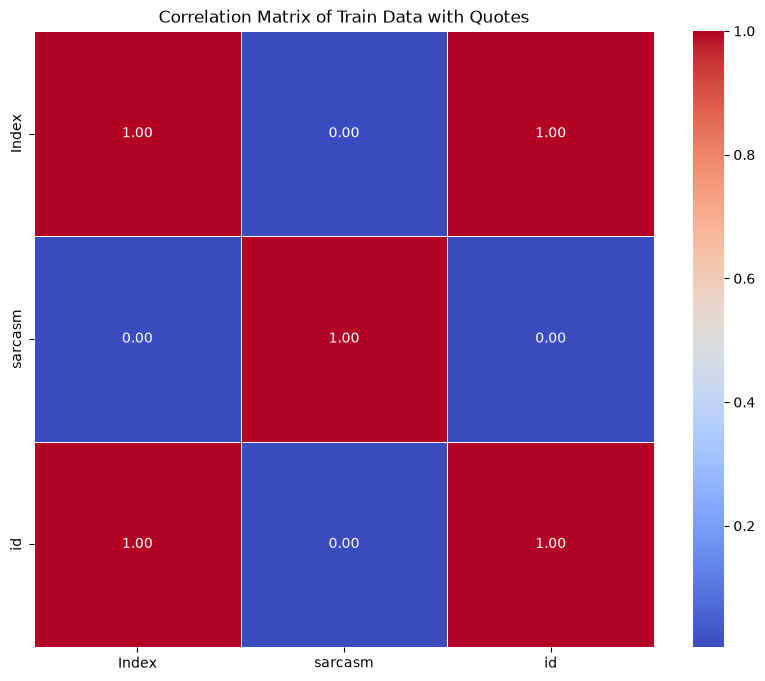

In [ ]:
import matplotlib.pyplot as plt 
import seaborn as sns

dialect_order = ['msa', 'egypt', 'levant', 'gulf', 'magreb']
sentiment_order = ['NEU', 'NEG', 'POS']



